# Safe authority for AI agents in a coupled city

A city runs coupled services (power, water, transport). Increasingly their operators are AI agents that read sensors, message each other, and propose actions. **How much authority can we give the agents, and how much may they talk, before one small error cascades city‑wide?**

The answer the project builds toward: write a nonnegative matrix $K$ that bounds how deficits propagate in one step; the system is safe iff the spectral radius $\rho(K) < 1$. Authority, communication, and mitigation are knobs that move entries of $K$.

| Section | Adds |
|---|---|
| 1 | The model, $\rho$, and the $2\times2$ condition $ce < (1-p)(1-a)$ |
| 2 | The knobs $(m, z, \gamma)$; a $4\times4$ example that is stable layer‑by‑layer but unstable together |
| 3 | A witness certificate that replaces sweeping over $\gamma$ with one formula |


## 1. The model

**Two kinds of coupling.** Services are *physically* coupled (power drops → pumps slow, signals fail). Agents are *informationally* coupled (messages). And the two layers touch: agents act on the plant and observe it. So there is a loop — agent error → deficit → observed deficit → agent error — and the question is whether the loop amplifies or damps.

**We track deficits, not state.** We don't model the city's full state (voltages, pressures, how much traffic there is). We only track how far each piece is from being fine, as a number from 0 up.

*For a service sector* (e.g. the water network):
$$d^P_i = \frac{\text{normal service} - \text{actual service}}{\text{normal service}}$$

- Delivering 100% of normal → $d^P = 0$ (no problem)
- Delivering 70% of normal → $d^P = 0.3$ (a 30% shortfall)

*For an AI agent:*
$$d^A_a = \frac{\text{how far its proposed action is from the correct action}}{\text{size of a typical action}}$$

- The agent proposes exactly the right action → $d^A = 0$
- The right move is "open the valve 10%" and it proposes "open it 15%" → it's off by 5 points on a typical 10-point action, so $d^A = 0.5$

Both are $\ge 0$ by construction. That lets us work with upper bounds instead of equations — and an upper bound is something we can write down without opening up a language model.

**Four matrices**, one per direction a deficit can travel:

| | direction | controlled by |
|---|---|---|
| $P$ | physical → physical (diagonal = persistence) | plant; later mitigation $m$ |
| $A$ | agent → agent via messages | communication $z$ |
| $C$ | agent → physical: **the only way an agent error becomes real** | authority $\gamma$ |
| $D$ | physical → agent: the agent sees a problem and reacts | nobody — fixed by the deployment |

$$
\begin{bmatrix} d^P_{t+1} \\ d^A_{t+1} \end{bmatrix}
\preceq
\underbrace{\begin{bmatrix} P & C \\ D & A \end{bmatrix}}_{K}
\begin{bmatrix} d^P_{t} \\ d^A_{t} \end{bmatrix} + \xi_t
\qquad (\preceq \text{ entrywise},\ \xi_t \ge 0 \text{ a disturbance})
$$

$C$ and $D$ are the only blocks where the layers touch. Zero either one and $K$ is block‑triangular: $\rho(K) = \max\{\rho(P), \rho(A)\}$ and the layers stop interacting.

**The one fact (Perron–Frobenius).** For $K \ge 0$: $\rho(K) < 1 \Rightarrow d_t \to 0$; $\rho(K) > 1 \Rightarrow d_t$ can grow without bound. $\rho$ is the per‑step growth factor of the worst‑case deficit profile, so the whole safety question is one number.

For a $2\times2$ matrix $\begin{bmatrix} p & c \\ e & a \end{bmatrix}$ the eigenvalues are $\lambda = \tfrac12\big[(p+a) \pm \sqrt{(p+a)^2 - 4(pa-ce)}\big]$, and for $p, a < 1$:

$$\boxed{\;\rho < 1 \iff c\,e < (1-p)(1-a)\;}$$

Left: authority × sensing, the gain of one trip around the loop. Right: the two layers' stability margins. **Safety is a product — it cannot be bought in one layer alone.**


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def rho(M):
    return float(np.max(np.abs(np.linalg.eigvals(np.asarray(M, float)))))

def iterate(M, d0, steps):
    d, out = np.asarray(d0, float), []
    for _ in range(steps + 1):
        out.append(d); d = M @ d
    return np.array(out)

def coupling_diagram(p, a, c, e, ax):
    """Two layers, four arrows; arrow width = gain."""
    ax.set_xlim(0, 10); ax.set_ylim(0, 6); ax.axis("off")
    for y, lbl, col in [(4.2, "agents  $d^A$", "#dbe9f6"), (0.6, "sectors  $d^P$", "#fde6c4")]:
        ax.add_patch(FancyBboxPatch((3, y), 4, 1.2, boxstyle="round,pad=0.15", fc=col, ec="k"))
        ax.text(5, y + 0.6, lbl, ha="center", va="center", fontsize=11)
    w = lambda g: 1 + 6*g
    arr = lambda s, t, g, col, **k: ax.add_patch(FancyArrowPatch(s, t, arrowstyle="-|>", mutation_scale=15, lw=w(g), color=col, **k))
    arr((7.2, 5.0), (7.2, 4.6), a, "#2a6db2", connectionstyle="arc3,rad=-2.2"); ax.text(8.9, 4.8, f"A = {a:.2f}", color="#2a6db2", ha="center")
    arr((7.2, 1.4), (7.2, 1.0), p, "#c66a00", connectionstyle="arc3,rad=-2.2"); ax.text(8.9, 1.2, f"P = {p:.2f}", color="#c66a00", ha="center")
    arr((4.2, 4.1), (4.2, 1.9), c, "#9b1c1c"); ax.text(2.9, 3.0, f"C = {c:.2f}\nauthority", color="#9b1c1c", ha="center")
    arr((5.8, 1.9), (5.8, 4.1), e, "#2e7d32"); ax.text(7.1, 3.0, f"D = {e:.2f}\nsensing", color="#2e7d32", ha="center")

## 2. Worked example: stable layers, unstable system

Two sectors, two agents, everything diagonal — so the $4\times4$ splits into two identical $2\times2$ problems $M = \begin{bmatrix} p & c \\ e & a \end{bmatrix}$. Take $p = a = 0.6$ (each layer alone has $\rho = 0.6$) and $c = e = 0.5$.


In [2]:
p, a, c, e = 0.6, 0.6, 0.5, 0.5
M = np.array([[p, c], [e, a]])
print(f"rho(P) = {p},  rho(A) = {a}   -> each layer alone is stable")
print(f"rho(M) = {rho(M):.2f}            -> coupled system is NOT")
print(f"ce = {c*e:.2f}  vs  (1-p)(1-a) = {(1-p)*(1-a):.2f}")

rho(P) = 0.6,  rho(A) = 0.6   -> each layer alone is stable
rho(M) = 1.10            -> coupled system is NOT
ce = 0.25  vs  (1-p)(1-a) = 0.16


Nothing malfunctioned and no agent lied; the instability is created entirely by the coupling. The interactive below is the whole of Section 1 in one picture — drag the four gains and watch $\rho$ and a 10% initial shortfall respond.

Try: drop $c$ to 0.3 (stable). Instead drop $p$ to 0.4 — "buy backup capacity" — same effect, different lever. Set $c=0$ or $e=0$: either cut kills the loop, but leaves agents that are useless or blind.


In [3]:
def show(p=0.6, a=0.6, c=0.5, e=0.5, steps=15):
    M = np.array([[p, c], [e, a]]); r = rho(M); traj = iterate(M, [0.1, 0], steps)
    fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw=dict(width_ratios=[1.1, 1]))
    coupling_diagram(p, a, c, e, ax0)
    ax0.set_title(f"rho = {r:.3f}   ce = {c*e:.2f}   (1-p)(1-a) = {(1-p)*(1-a):.2f}   ->  {'SAFE' if r < 1 else 'UNSAFE'}",
                  color="#2e7d32" if r < 1 else "#9b1c1c")
    ax1.plot(traj[:, 0], "o-", color="#c66a00", label="sector deficit"); ax1.plot(traj[:, 1], "s-", color="#2a6db2", label="agent error")
    ax1.set_xlabel("step"); ax1.set_ylabel("deficit"); ax1.grid(alpha=.3); ax1.legend(); ax1.set_title("from a 10% shortfall")
    plt.tight_layout(); plt.show()

try:
    from ipywidgets import interact, FloatSlider as S
    interact(show, p=S(value=.6, min=0, max=.99, step=.01), a=S(value=.6, min=0, max=.99, step=.01),
                   c=S(value=.5, min=0, max=1.5, step=.01), e=S(value=.5, min=0, max=1.5, step=.01), steps=(3, 40));
except ImportError:
    show()

interactive(children=(FloatSlider(value=0.6, description='p', max=0.99, step=0.01), FloatSlider(value=0.6, des…

The boundary $ce = (1-p)(1-a)$ is a hyperbola in the (authority, sensing) plane. Lowering $p$ pushes the whole curve outward — mitigation buys authority at every sensing level at once.

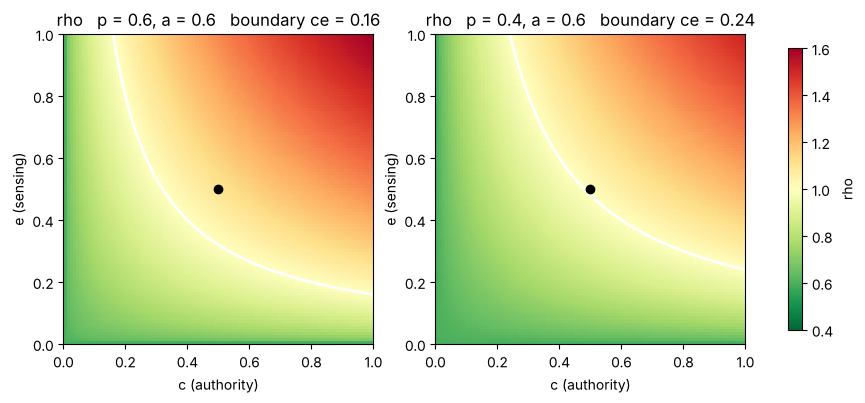

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
g = np.linspace(0, 1, 101)
for ax, p in zip(axes, [0.6, 0.4]):
    R = np.array([[rho([[p, c], [e, 0.6]]) for c in g] for e in g])
    im = ax.imshow(R, origin="lower", extent=[0, 1, 0, 1], vmin=.4, vmax=1.6, cmap="RdYlGn_r")
    ax.contour(g, g, R, levels=[1], colors="w", linewidths=2)
    ax.plot(.5, .5, "ko"); ax.set_xlabel("c (authority)"); ax.set_ylabel("e (sensing)")
    ax.set_title(f"rho   p = {p}, a = 0.6   boundary ce = {(1-p)*0.4:.2f}")
fig.colorbar(im, ax=axes, shrink=.85, label="rho"); plt.show()

## Where this leaves us

- Safe iff $\rho(K) < 1$; in the toy, iff $ce < (1-p)(1-a)$.
- Two individually stable layers can be jointly unstable, and the instability lives in the *product* of the cross‑couplings.

What's missing: the numbers were handed to us. In reality $P$, $A$, $C$ are shaped by decisions — mitigation $m$, communication $z$, authority $\gamma$ — and only $D$ is fixed. Section 2 names those knobs and finds the safe authority level by sweeping; Section 3 replaces the sweep with a formula.

*Carry‑over question:* if you could set $c=0$ or $e=0$ but not both, which? Section 2 will show that $e$ (sensing) isn't ours to set at all.

---
